# Predicción de deserción al cierre del primer semestre

## 1. Objetivo y modelos

Queremos ordenar a los estudiantes por riesgo de deserción para priorizar el seguimiento al cierre del primer semestre. La clase positiva es `Target = 1`.

| Candidato | Qué queremos comprobar |
|---|---|
| Árbol de decisión | Cuánto se puede predecir con un conjunto de reglas fácil de explicar. |
| Random Forest | Si combinar árboles entrenados con distintas muestras mejora la clasificación. |
| Red neuronal MLP | Si una red pequeña aprende relaciones útiles entre las variables de entrada. |
| Gradient Boosting | Si agregar árboles poco profundos en secuencia mejora el ordenamiento. |
| Ensamble 50/50 | Si promediar las probabilidades de Gradient Boosting y de la MLP aprovecha señales complementarias. |

## 2. Métricas y criterio de comparación

| Métrica | Interpretación y uso |
|---|---|
| **Average precision (AP)** | Resume la precisión conforme se recuperan más casos de deserción. Es el criterio principal de ajuste y selección. La proporción de desertores, cerca de 0.32, sirve como referencia de un ordenamiento sin señal. |
| **ROC-AUC** | Mide qué tan bien se ordena a quienes desertan por encima de quienes no desertan, dando medio crédito a los empates. Se reporta como complemento. |

Para una futura regla de seguimiento, la **precisión entre los primeros K** mide la proporción de desertores dentro de los cupos disponibles. El **recall entre los primeros K** mide qué proporción de todos los desertores se detecta con esos cupos. Estas métricas requieren definir la capacidad de atención. Si el tablero muestra probabilidades individuales, conviene evaluar también su calibración.

La comparación usa cinco pliegues estratificados sobre el 80 % de entrenamiento. Los resultados orientan la selección y pueden ser optimistas porque los mismos pliegues se usaron para ajustar hiperparámetros. El 20 % de prueba queda reservado para la evaluación final.

## 3. Datos y selección de variables

La selección se basa en la disponibilidad de la información y en los hallazgos de *Exploracion de datos.ipynb*, en particular las secciones de asociación con la deserción y fuga de información.

La exploración destacó la tasa de aprobación, las materias aprobadas y la nota del primer semestre. Usamos esas señales junto con variables de ingreso para permitir que los modelos encuentren relaciones entre ellas. Conservamos la tasa y el conteo de aprobadas porque describen aspectos distintos de la carga académica.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import average_precision_score
import mlflow
from datetime import datetime


c:\Users\herna\miniconda3\envs\analytics\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
display(Markdown("""
### 3.1 Cargar y verificar la versión de DVC
La columna `Target` ya es binaria. Usamos `1` para deserción.
"""))

# Leer el CSV de DVC y verificar la codificación del objetivo.
ruta = Path("data/students_dropout.csv")
datos = pd.read_csv(ruta)
y = datos["Target"]
assert y.notna().all() and set(y.unique()) == {0, 1}, "Se esperaba Target binario con valores 0 y 1."

display(pd.DataFrame({"estudiantes": y.value_counts(), "proporción": y.value_counts(normalize=True)}).sort_index())


### 3.1 Cargar y verificar la versión de DVC
La columna `Target` ya es binaria. Usamos `1` para deserción.


,estudiantes,proporción
Target,,
0,3003,0.678797
1,1421,0.321203


In [3]:
display(Markdown("""
### 3.2 Definir las variables candidatas

La predicción se hará al cierre del primer semestre. La exploración mostró que la nota, 
la aprobación y el estado académico de ese semestre concentran varias de las señales más fuertes.
Conservamos también las demás variables candidatas porque el árbol puede encontrar relaciones entre ellas.

- Excluimos las variables del segundo semestre y sus derivadas por fuga temporal.
- Excluimos deuda, beca y matrícula al día hasta confirmar cuándo se midieron.
- Conservamos las variables macroeconómicas en esta primera comparación. La
  exploración observó que juntas identifican cohortes, por lo que una
  validación aleatoria mide desempeño entre estudiantes de cohortes mezcladas.
- Para los casos `no_inscrito`, tratamos los ceros curriculares como faltantes
  según la hipótesis de la exploración y conservamos la categoría académica.
"""))

# Normalizar los encabezados antes de identificar las columnas.
datos = datos.rename(columns=lambda nombre: nombre.strip().removesuffix(r"\t").strip())

# Excluir información posterior al corte y variables de fecha incierta.
segundo_semestre = [
    columna for columna in datos.columns
    if columna.startswith("Curricular units 2nd sem") or columna.endswith("_2nd")
]
fecha_por_confirmar = ["Debtor", "Scholarship holder", "Tuition fees up to date"]
X = datos.drop(columns=["Target"] + segundo_semestre + fecha_por_confirmar).copy()

# separar las variables
categoricas = [
    "Marital status", "Application mode", "Course", "Daytime/evening attendance",
    "Previous qualification", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation", "estado_1st",
]
binarias = ["Displaced", "Gender", "es_adulto"]
numericas = X.columns.drop(categoricas + binarias).tolist()

for columna in binarias:
    assert X[columna].dropna().isin([0, 1]).all(), f"{columna} debe estar codificada como 0/1."

# marca como faltante el bloque curricular de los casos sin registro.
sin_registro = X["estado_1st"].eq("no_inscrito")
curriculares = [
    columna for columna in X.columns
    if columna.startswith("Curricular units 1st sem")
]
X.loc[sin_registro, curriculares + ["tasa_aprob_1st"]] = float("nan")

display(Markdown("""
### Cómo se representan las variables?

- **Numéricas:** el árbol prueba umbrales. Imputamos los faltantes con la mediana aprendida en cada pliegue.
- **Categóricas:** una columna indicadora por categoría evita dar un orden artificial a códigos como los de programa.
- **Binarias:** una columna por variable permite separar 0 y 1 con un umbral de 0.5. Si hay faltantes,
se imputan con el valor más frecuente del pliegue.
"""))

print(f"Variables candidatas: {X.shape[1]}")
display(pd.Series({
    "Numéricas": len(numericas),
    "Categóricas": len(categoricas),
    "Binarias": len(binarias),
}, name="columnas").to_frame())
display(X.isna().sum().rename("faltantes").to_frame())


### 3.2 Definir las variables candidatas

La predicción se hará al cierre del primer semestre. La exploración mostró que la nota, 
la aprobación y el estado académico de ese semestre concentran varias de las señales más fuertes.
Conservamos también las demás variables candidatas porque el árbol puede encontrar relaciones entre ellas.

- Excluimos las variables del segundo semestre y sus derivadas por fuga temporal.
- Excluimos deuda, beca y matrícula al día hasta confirmar cuándo se midieron.
- Conservamos las variables macroeconómicas en esta primera comparación. La
  exploración observó que juntas identifican cohortes, por lo que una
  validación aleatoria mide desempeño entre estudiantes de cohortes mezcladas.
- Para los casos `no_inscrito`, tratamos los ceros curriculares como faltantes
  según la hipótesis de la exploración y conservamos la categoría académica.



### Cómo se representan las variables?

- **Numéricas:** el árbol prueba umbrales. Imputamos los faltantes con la mediana aprendida en cada pliegue.
- **Categóricas:** una columna indicadora por categoría evita dar un orden artificial a códigos como los de programa.
- **Binarias:** una columna por variable permite separar 0 y 1 con un umbral de 0.5. Si hay faltantes,
se imputan con el valor más frecuente del pliegue.


Variables candidatas: 27


,columnas
Numéricas,14
Categóricas,10
Binarias,3


,faltantes
Marital status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance,0
Previous qualification,0
Previous qualification (grade),0
Mother's qualification,0
Father's qualification,0
Mother's occupation,0


In [4]:
display(Markdown("""
## 4. Protocolo de validación
Reservamos el 20% de los estudiantes para la muestra de test.
"""))

semilla = 42
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=semilla
)
print(f"Train: {len(y_entrenamiento)} | Test: {len(y_prueba)}")


## 4. Protocolo de validación
Reservamos el 20% de los estudiantes para la muestra de test.


Train: 3539 | Test: 885


In [5]:
display(Markdown("""
## 5. Exploración de modelos
### 5.1 Arboles de decisión

#### 5.1.1 Configuración inicial
La imputación y la codificación se ajustan dentro de cada pliegue. Usamos un árbol de profundidad 4 como referencia inicial.
La métrica principal es `average_precision`, que resume el desempeño al identificar la clase de deserción a través de distintos umbrales.
"""))

# imputacion y la codificación dentro de cada pliegue.
preprocesamiento = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="median"), numericas),
    ("binarias", SimpleImputer(strategy="most_frequent"), binarias),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas),
])

modelo = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("arbol", DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=semilla)),
])

pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)

# AP y ROC-AUC sobre los estudiantes de validación.
resultados = cross_validate(
    modelo, X_entrenamiento, y_entrenamiento, cv=pliegues,
    scoring=["average_precision", "roc_auc"], error_score="raise",
)
metricas = pd.DataFrame({
    "average_precision": resultados["test_average_precision"],
    "roc_auc": resultados["test_roc_auc"],
}, index=pd.RangeIndex(1, 6, name="pliegue"))

display(metricas.round(3))
display(metricas.agg(["mean", "std"]).rename(index={"mean": "media", "std": "desviación"}).round(3))


## 5. Exploración de modelos
### 5.1 Arboles de decisión

#### 5.1.1 Configuración inicial
La imputación y la codificación se ajustan dentro de cada pliegue. Usamos un árbol de profundidad 4 como referencia inicial.
La métrica principal es `average_precision`, que resume el desempeño al identificar la clase de deserción a través de distintos umbrales.


,average_precision,roc_auc
pliegue,,
1,0.746,0.840
2,0.743,0.832
3,0.754,0.866
4,0.743,0.840
5,0.765,0.860


,average_precision,roc_auc
media,0.750,0.848
desviación,0.009,0.014


In [6]:
display(Markdown("""
#### 5.1.2 Ajuste por grid

La profundidad máxima limita cuántas divisiones puede encadenar el árbol. El mínimo por hoja limita las
reglas que se apoyan en pocos estudiantes. Probamos 12 combinaciones, incluida la configuración inicial (4, 20),
sobre los mismos cinco pliegues.

Con `refit="average_precision"`, la mejor configuración se vuelve a entrenar con todo el 80 % de train.
El 20 % de test queda reservado para cuando se elija el modelo final.
"""))

# Evaluar la cuadrícula y reajustar la mejor configuración por AP.
busqueda_arbol = GridSearchCV(
    estimator=modelo,
    param_grid={
        "arbol__max_depth": [2, 4, 6, 8],
        "arbol__min_samples_leaf": [10, 20, 40],
    },
    scoring=["average_precision", "roc_auc"],
    refit="average_precision",
    cv=pliegues,
    error_score="raise",
)
busqueda_arbol.fit(X_entrenamiento, y_entrenamiento)
mejor_arbol = busqueda_arbol.best_estimator_

comparacion = pd.DataFrame(busqueda_arbol.cv_results_)
columnas = [
    "param_arbol__max_depth",
    "param_arbol__min_samples_leaf",
    "mean_test_average_precision",
    "std_test_average_precision",
    "mean_test_roc_auc",
]
display(comparacion.sort_values("rank_test_average_precision")[columnas]
        .reset_index(drop=True).round(4))

ap_base = metricas["average_precision"].mean()
display(Markdown(f"""
**Mejor configuración:** `{busqueda_arbol.best_params_}`

- Precisión promedio del árbol inicial: **{ap_base:.4f}**
- Precisión promedio de la mejor configuración: **{busqueda_arbol.best_score_:.4f}**
- Diferencia media en los mismos pliegues: **{busqueda_arbol.best_score_ - ap_base:+.4f}**
"""))


#### 5.1.2 Ajuste por grid

La profundidad máxima limita cuántas divisiones puede encadenar el árbol. El mínimo por hoja limita las
reglas que se apoyan en pocos estudiantes. Probamos 12 combinaciones, incluida la configuración inicial (4, 20),
sobre los mismos cinco pliegues.

Con `refit="average_precision"`, la mejor configuración se vuelve a entrenar con todo el 80 % de train.
El 20 % de test queda reservado para cuando se elija el modelo final.


,param_arbol__max_depth,param_arbol__min_samples_leaf,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc
0,8,40,0.7725,0.0205,0.8473
1,6,40,0.7692,0.0208,0.8479
2,8,20,0.7592,0.0166,0.8384
3,6,20,0.7558,0.0128,0.8412
4,4,40,0.7555,0.0100,0.8485
5,4,20,0.7502,0.0082,0.8475
6,6,10,0.7471,0.0118,0.8382
7,4,10,0.7463,0.0125,0.8464
8,8,10,0.7284,0.0243,0.8294
9,2,20,0.6807,0.0128,0.8132



**Mejor configuración:** `{'arbol__max_depth': 8, 'arbol__min_samples_leaf': 40}`

- Precisión promedio del árbol inicial: **0.7502**
- Precisión promedio de la mejor configuración: **0.7725**
- Diferencia media en los mismos pliegues: **+0.0223**


In [7]:
# Prueba conexion MLFLow
# Conectar el notebook al servidor de EC2.
mlflow.set_tracking_uri("http://54.227.177.156:8050")
mlflow.set_experiment("prueba-conexion-desercionV2")


# Registrar una corrida para verificar la conexión.
with mlflow.start_run(run_name="prueba-desde-notebook") as corrida:
    mlflow.log_param("origen", "notebook_local")
    mlflow.log_metric("conexion_ok", 1)

print(f"Corrida registrada: {corrida.info.run_id}")

🏃 View run prueba-desde-notebook at: http://54.227.177.156:8050/#/experiments/3/runs/1125e0a371ee48879ae5ee18b6a0cded
🧪 View experiment at: http://54.227.177.156:8050/#/experiments/3


Corrida registrada: 1125e0a371ee48879ae5ee18b6a0cded


In [8]:
display(Markdown("""
#### 5.1.3 Registro en MLFlow

Procedemos a registrar cada modelo en MLFlow para facilitar su visualización y comparación. Cada corrida contiene los hiperparámetros,
las métricas de validación por pliegue y sus medias.

"""))


mlflow.set_tracking_uri("http://54.227.177.156:8050")
mlflow.set_experiment("entrega-2-desercion-V2")

grupo = datetime.now().strftime("%Y%m%d-%H%M%S")
resultados_cv = busqueda_arbol.cv_results_

for indice, parametros in enumerate(resultados_cv["params"]):
    profundidad = parametros["arbol__max_depth"]
    minimo_hoja = parametros["arbol__min_samples_leaf"]

    nombre = f"arbol-profundidad-{profundidad}-hoja-{minimo_hoja}"

    with mlflow.start_run(run_name=nombre):
        # Guardar la configuración y las condiciones de validación.
        mlflow.log_params({
            "max_depth": profundidad,
            "min_samples_leaf": minimo_hoja,
            "random_state": semilla,
            "n_pliegues": pliegues.get_n_splits(),
            "n_variables": X_entrenamiento.shape[1],
            "n_entrenamiento": len(y_entrenamiento),
            "n_prueba_reservados": len(y_prueba),
        })

        mlflow.set_tags({
            "familia": "arbol_decision",
            "grupo_registro": grupo,
            "seleccionado_en_familia": str(
                indice == busqueda_arbol.best_index_
            ).lower(),
            "origen_resultados": "GridSearchCV",
        })

        # Registrar las medias y dispersiones calculadas por la búsqueda.
        mlflow.log_metrics({
            "cv_ap_mean": float(
                resultados_cv["mean_test_average_precision"][indice]
            ),
            "cv_ap_std": float(
                resultados_cv["std_test_average_precision"][indice]
            ),
            "cv_roc_auc_mean": float(
                resultados_cv["mean_test_roc_auc"][indice]
            ),
            "cv_roc_auc_std": float(
                resultados_cv["std_test_roc_auc"][indice]
            ),
        })

        # Conservar el desempeño de cada pliegue.
        for pliegue in range(pliegues.get_n_splits()):
            mlflow.log_metrics({
                f"cv_ap_fold_{pliegue + 1}": float(
                    resultados_cv[
                        f"split{pliegue}_test_average_precision"
                    ][indice]
                ),
                f"cv_roc_auc_fold_{pliegue + 1}": float(
                    resultados_cv[
                        f"split{pliegue}_test_roc_auc"
                    ][indice]
                ),
            })

        # Documentar las columnas y su tratamiento.
        mlflow.log_dict({
            "numericas": numericas,
            "categoricas": categoricas,
            "binarias": binarias,
        }, "variables.json")

print(f"Registradas {len(resultados_cv['params'])} configuraciones.")
print(f"Grupo de registro: {grupo}")


#### 5.1.3 Registro en MLFlow

Procedemos a registrar cada modelo en MLFlow para facilitar su visualización y comparación. Cada corrida contiene los hiperparámetros,
las métricas de validación por pliegue y sus medias.



2026/11/06 23:38:01 INFO mlflow.tracking.fluent: Experiment with name 'entrega-2-desercion-V2' does not exist. Creating a new experiment.


🏃 View run arbol-profundidad-2-hoja-10 at: http://34.228.198.254:8050/#/experiments/4/runs/655a6d223c9d40bca973ebb030a136e2
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run arbol-profundidad-2-hoja-20 at: http://34.228.198.254:8050/#/experiments/4/runs/2e9e04416c9f426ea6dd96e78775b743
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run arbol-profundidad-2-hoja-40 at: http://34.228.198.254:8050/#/experiments/4/runs/1e891e7464d744b0b3e8741fb19a671d
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run arbol-profundidad-4-hoja-10 at: http://34.228.198.254:8050/#/experiments/4/runs/ed523b5d4eac459794b121ac38c26e16
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run arbol-profundidad-4-hoja-20 at: http://34.228.198.254:8050/#/experiments/4/runs/063e20cd796a41b1894a429df1bd9d7a
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run arbol-profundidad-4-hoja-40 at: http://34.22

In [9]:
display(Markdown("""
### 5.2 Random Forest

#### 5.2.1 Configuración inicial

Un Random Forest combina las predicciones de muchos árboles. Cada árbol se entrena con una muestra de estudiantes
y considera un subconjunto de variables en cada división. Esto reduce cuánto depende la predicción de
las reglas aprendidas por un solo árbol.

Conservamos las variables, el preprocesamiento y los cinco pliegues del experimento anterior para
comparar los resultados. Usamos 300 árboles como configuración inicial.
"""))

# Crear el bosque con 300 árboles y los parámetros de la referencia.
modelo_forest = Pipeline([
    ("preprocesamiento", clone(preprocesamiento)),
    ("forest", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=1,
        random_state=semilla,
        n_jobs=-1,
    )),
])

# Medir AP y ROC-AUC sobre los estudiantes de validación.
resultados_forest = cross_validate(
    modelo_forest,
    X_entrenamiento,
    y_entrenamiento,
    cv=pliegues,
    scoring=["average_precision", "roc_auc"],
    error_score="raise",
)

metricas_forest = pd.DataFrame({
    "average_precision": resultados_forest["test_average_precision"],
    "roc_auc": resultados_forest["test_roc_auc"],
}, index=pd.RangeIndex(1, 6, name="pliegue"))

display(metricas_forest.round(4))
display(
    metricas_forest.agg(["mean", "std"])
    .rename(index={"mean": "media", "std": "desviación"})
    .round(4)
)


### 5.2 Random Forest

#### 5.2.1 Configuración inicial

Un Random Forest combina las predicciones de muchos árboles. Cada árbol se entrena con una muestra de estudiantes
y considera un subconjunto de variables en cada división. Esto reduce cuánto depende la predicción de
las reglas aprendidas por un solo árbol.

Conservamos las variables, el preprocesamiento y los cinco pliegues del experimento anterior para
comparar los resultados. Usamos 300 árboles como configuración inicial.


,average_precision,roc_auc
pliegue,,
1,0.8003,0.8725
2,0.8086,0.8623
3,0.8004,0.8844
4,0.8100,0.8666
5,0.8401,0.8994


,average_precision,roc_auc
media,0.8119,0.877
desviación,0.0164,0.015


In [10]:
display(Markdown("""
#### 5.2.2 Ajuste por grid

Probamos profundidades máximas de 6, 12 y sin límite para evaluar cuánto conviene restringir la complejidad de cada árbol. También
probamos mínimos de 1, 5 y 15 estudiantes por hoja para medir el efecto de exigir que cada predicción se apoye en más observaciones.
"""))

assert modelo_forest.get_params()["forest__n_estimators"] == 300, (
    "Ejecuta primero la línea base con 300 árboles."
)

busqueda_forest = GridSearchCV(
    estimator=modelo_forest,
    param_grid={
        "forest__max_depth": [6, 12, None],
        "forest__min_samples_leaf": [1, 5, 15],
    },
    scoring=["average_precision", "roc_auc"],
    refit="average_precision",
    cv=pliegues,
    error_score="raise",
    verbose=1,
)
busqueda_forest.fit(X_entrenamiento, y_entrenamiento)
mejor_forest = busqueda_forest.best_estimator_

comparacion_forest = pd.DataFrame(busqueda_forest.cv_results_)
columnas_forest = [
    "param_forest__max_depth",
    "param_forest__min_samples_leaf",
    "mean_test_average_precision",
    "std_test_average_precision",
    "mean_test_roc_auc",
]
display(
    comparacion_forest.sort_values("rank_test_average_precision")[columnas_forest]
    .reset_index(drop=True)
    .round(4)
)

ap_base = metricas_forest["average_precision"].mean()
ap_mejor = busqueda_forest.best_score_

display(Markdown(f"""
**Mejor configuración** `{busqueda_forest.best_params_}`

- Precisión promedio de la línea base **{ap_base:.4f}**
- Precisión promedio de la mejor configuración **{ap_mejor:.4f}**
- Diferencia frente a la línea base **{(ap_mejor - ap_base) * 100:+.2f} puntos porcentuales**
"""))


#### 5.2.2 Ajuste por grid

Probamos profundidades máximas de 6, 12 y sin límite para evaluar cuánto conviene restringir la complejidad de cada árbol. También
probamos mínimos de 1, 5 y 15 estudiantes por hoja para medir el efecto de exigir que cada predicción se apoye en más observaciones.


Fitting 5 folds for each of 9 candidates, totalling 45 fits


,param_forest__max_depth,param_forest__min_samples_leaf,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc
0,12,5,0.8142,0.0125,0.8759
1,None,5,0.8138,0.0141,0.8763
2,12,1,0.8137,0.0118,0.8778
3,None,1,0.8119,0.0147,0.8770
4,None,15,0.8084,0.0132,0.8729
5,6,1,0.8084,0.0139,0.8702
6,12,15,0.8082,0.0136,0.8729
7,6,5,0.8078,0.0139,0.8704
8,6,15,0.8060,0.0141,0.8692



**Mejor configuración** `{'forest__max_depth': 12, 'forest__min_samples_leaf': 5}`

- Precisión promedio de la línea base **0.8119**
- Precisión promedio de la mejor configuración **0.8142**
- Diferencia frente a la línea base **+0.23 puntos porcentuales**


In [11]:
display(Markdown("""
#### 5.2.3 Registro en MLFlow
"""))

resultados_cv = busqueda_forest.cv_results_

for indice, parametros in enumerate(resultados_cv["params"]):
    profundidad = parametros["forest__max_depth"]
    minimo_hoja = parametros["forest__min_samples_leaf"]

    with mlflow.start_run(
        run_name=f"forest-profundidad-{profundidad}-hoja-{minimo_hoja}"
    ):
        # Guardar los parámetros variables y los que permanecieron fijos.
        mlflow.log_params({
            "n_estimators": 300,
            "max_depth": str(profundidad),
            "min_samples_leaf": minimo_hoja,
            "max_features": modelo_forest.get_params()["forest__max_features"],
            "random_state": semilla,
            "n_pliegues": pliegues.get_n_splits(),
            "n_variables": X_entrenamiento.shape[1],
            "n_entrenamiento": len(y_entrenamiento),
            "n_prueba_reservados": len(y_prueba),
        })

        mlflow.set_tags({
            "familia": "random_forest",
            "grupo_registro": grupo,
            "seleccionado_en_familia": str(
                indice == busqueda_forest.best_index_
            ).lower(),
            "origen_resultados": "GridSearchCV",
        })

        # Registrar medias y desviaciones de ambas métricas.
        for metrica, nombre_corto in [
            ("average_precision", "ap"),
            ("roc_auc", "roc_auc"),
        ]:
            mlflow.log_metrics({
                f"cv_{nombre_corto}_mean": float(
                    resultados_cv[f"mean_test_{metrica}"][indice]
                ),
                f"cv_{nombre_corto}_std": float(
                    resultados_cv[f"std_test_{metrica}"][indice]
                ),
            })

            # Registrar también los resultados individuales de los pliegues.
            for pliegue in range(pliegues.get_n_splits()):
                mlflow.log_metric(
                    f"cv_{nombre_corto}_fold_{pliegue + 1}",
                    float(resultados_cv[f"split{pliegue}_test_{metrica}"][indice]),
                )

        mlflow.log_dict({
            "numericas": numericas,
            "categoricas": categoricas,
            "binarias": binarias,
        }, "variables.json")

print(f"Registradas {len(resultados_cv['params'])} configuraciones de Random Forest.")


#### 5.2.3 Registro en MLFlow


🏃 View run forest-profundidad-6-hoja-1 at: http://34.228.198.254:8050/#/experiments/4/runs/a247c3680c4747939b39615414f57d7c
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run forest-profundidad-6-hoja-5 at: http://34.228.198.254:8050/#/experiments/4/runs/a8754676dfc64d529ff0c77fac2bfb84
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run forest-profundidad-6-hoja-15 at: http://34.228.198.254:8050/#/experiments/4/runs/9d32cb86f0924258bd0eb9ff9e3cf4bf
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run forest-profundidad-12-hoja-1 at: http://34.228.198.254:8050/#/experiments/4/runs/f0616e3547904ad9a82411941b33591d
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run forest-profundidad-12-hoja-5 at: http://34.228.198.254:8050/#/experiments/4/runs/6e67e36929754b829f0cfa991b68136c
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run forest-profundidad-12-hoja-15 at: http://

In [12]:
display(Markdown("""
### 5.3 Red neuronal MLP

#### 5.3.1 Configuración inicial

Probamos una red con una capa oculta de 32 neuronas. Empezamos con una arquitectura pequeña dado el tamaño del conjunto de entrenamiento.

Escalamos las variables numéricas después de imputar sus faltantes. El pipeline aprende
la mediana, el escalado y la codificación de categorías con el entrenamiento de cada pliegue,
usamos las mismas variables y particiones que en el Random Forest.
"""))

preprocesamiento_mlp = clone(preprocesamiento)
preprocesamiento_mlp.set_params(
    numericas=Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("escalado", StandardScaler()),
    ])
)

modelo_mlp = Pipeline([
    ("preprocesamiento", preprocesamiento_mlp),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(32,),
        alpha=0.001,
        early_stopping=True,
        max_iter=300,
        random_state=semilla,
    )),
])

resultados_mlp = cross_validate(
    modelo_mlp,
    X_entrenamiento,
    y_entrenamiento,
    cv=pliegues,
    scoring=["average_precision", "roc_auc"],
    error_score="raise",
)

metricas_mlp = pd.DataFrame({
    "average_precision": resultados_mlp["test_average_precision"],
    "roc_auc": resultados_mlp["test_roc_auc"],
}, index=pd.RangeIndex(1, pliegues.get_n_splits() + 1, name="pliegue"))

display(metricas_mlp.round(4))
display(
    metricas_mlp.agg(["mean", "std"])
    .rename(index={"mean": "media", "std": "desviación"})
    .round(4)
)


### 5.3 Red neuronal MLP

#### 5.3.1 Configuración inicial

Probamos una red con una capa oculta de 32 neuronas. Empezamos con una arquitectura pequeña dado el tamaño del conjunto de entrenamiento.

Escalamos las variables numéricas después de imputar sus faltantes. El pipeline aprende
la mediana, el escalado y la codificación de categorías con el entrenamiento de cada pliegue,
usamos las mismas variables y particiones que en el Random Forest.


,average_precision,roc_auc
pliegue,,
1,0.7882,0.8665
2,0.8041,0.8620
3,0.7970,0.8709
4,0.8227,0.8765
5,0.8335,0.8931


,average_precision,roc_auc
media,0.8091,0.8738
desviación,0.0186,0.0120


In [13]:
display(Markdown("""
#### 5.3.2 Ajuste por grid

Comparamos dos redes de una capa oculta, con 32 y 64 neuronas, y una red de dos capas ocultas,
con 64 y 32 neuronas. Esto permite evaluar si una red con mayor capacidad aprovecha mejor las variables.

Probamos tres valores de `alpha`. Un valor mayor penaliza más los pesos grandes y puede ayudar a controlar el overfitting.
Mantenemos el mismo preprocesamiento, el early stopping y los cinco pliegues para comparar con la configuración inicial.
"""))

busqueda_mlp = GridSearchCV(
    estimator=modelo_mlp,
    param_grid={
        "mlp__hidden_layer_sizes": [(32,), (64,), (64, 32)],
        "mlp__alpha": [0.0001, 0.001, 0.01],
    },
    scoring=["average_precision", "roc_auc"],
    refit="average_precision",
    cv=pliegues,
    error_score="raise",
    verbose=1,
)

busqueda_mlp.fit(X_entrenamiento, y_entrenamiento)
mejor_mlp = busqueda_mlp.best_estimator_

comparacion_mlp = pd.DataFrame(busqueda_mlp.cv_results_)
columnas_mlp = [
    "param_mlp__hidden_layer_sizes",
    "param_mlp__alpha",
    "mean_test_average_precision",
    "std_test_average_precision",
    "mean_test_roc_auc",
]

display(
    comparacion_mlp.sort_values("rank_test_average_precision")[columnas_mlp]
    .reset_index(drop=True)
    .round(4)
)

ap_mlp_base = metricas_mlp["average_precision"].mean()
ap_mlp_mejor = busqueda_mlp.best_score_
ap_forest_mejor = busqueda_forest.best_score_

display(Markdown(f"""
**Mejor configuración** `{busqueda_mlp.best_params_}`

- Precisión promedio de la MLP inicial **{ap_mlp_base:.4f}**
- Precisión promedio de la MLP ajustada **{ap_mlp_mejor:.4f}**
- Precisión promedio del Random Forest ajustado **{ap_forest_mejor:.4f}**
- Diferencia MLP ajustada frente al bosque **{(ap_mlp_mejor - ap_forest_mejor) * 100:+.2f} puntos porcentuales**
"""))


#### 5.3.2 Ajuste por grid

Comparamos dos redes de una capa oculta, con 32 y 64 neuronas, y una red de dos capas ocultas,
con 64 y 32 neuronas. Esto permite evaluar si una red con mayor capacidad aprovecha mejor las variables.

Probamos tres valores de `alpha`. Un valor mayor penaliza más los pesos grandes y puede ayudar a controlar el overfitting.
Mantenemos el mismo preprocesamiento, el early stopping y los cinco pliegues para comparar con la configuración inicial.


Fitting 5 folds for each of 9 candidates, totalling 45 fits


,param_mlp__hidden_layer_sizes,param_mlp__alpha,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc
0,"(64, 32)",0.0001,0.8175,0.0115,0.8765
1,"(64, 32)",0.0100,0.8174,0.0115,0.8764
2,"(64, 32)",0.0010,0.8154,0.0125,0.8763
3,"(64,)",0.0100,0.8131,0.0159,0.8776
4,"(64,)",0.0010,0.8129,0.0156,0.8777
5,"(64,)",0.0001,0.8129,0.0156,0.8777
6,"(32,)",0.0100,0.8092,0.0167,0.8739
7,"(32,)",0.0010,0.8091,0.0166,0.8738
8,"(32,)",0.0001,0.8090,0.0166,0.8737



**Mejor configuración** `{'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (64, 32)}`

- Precisión promedio de la MLP inicial **0.8091**
- Precisión promedio de la MLP ajustada **0.8175**
- Precisión promedio del Random Forest ajustado **0.8142**
- Diferencia MLP ajustada frente al bosque **+0.34 puntos porcentuales**


In [14]:
display(Markdown("""
#### 5.3.3 Registro en MLFlow
"""))

grupo_mlp = datetime.now().strftime("%Y%m%d-%H%M%S")
resultados_cv = busqueda_mlp.cv_results_
parametros_base = modelo_mlp.named_steps["mlp"].get_params()

for indice, parametros in enumerate(resultados_cv["params"]):
    capas = parametros["mlp__hidden_layer_sizes"]
    alpha = parametros["mlp__alpha"]
    arquitectura = "-".join(str(neuronas) for neuronas in capas)

    with mlflow.start_run(
        run_name=f"mlp-capas-{arquitectura}-alpha-{alpha}"
    ):
        # Documentar la configuración de entrenamiento.
        mlflow.log_params({
            "hidden_layer_sizes": str(capas),
            "alpha": alpha,
            "activation": parametros_base["activation"],
            "solver": parametros_base["solver"],
            "learning_rate_init": parametros_base["learning_rate_init"],
            "batch_size": parametros_base["batch_size"],
            "max_iter": parametros_base["max_iter"],
            "early_stopping": parametros_base["early_stopping"],
            "validation_fraction": parametros_base["validation_fraction"],
            "random_state": parametros_base["random_state"],
            "n_pliegues": pliegues.get_n_splits(),
            "n_variables": X_entrenamiento.shape[1],
            "n_entrenamiento": len(y_entrenamiento),
            "n_prueba_reservados": len(y_prueba),
        })

        mlflow.set_tags({
            "familia": "mlp",
            "grupo_registro": grupo_mlp,
            "seleccionado_en_familia": str(
                indice == busqueda_mlp.best_index_
            ).lower(),
            "origen_resultados": "GridSearchCV",
        })

        # Registrar los promedios y la dispersión entre pliegues.
        for metrica, nombre_corto in [
            ("average_precision", "ap"),
            ("roc_auc", "roc_auc"),
        ]:
            mlflow.log_metrics({
                f"cv_{nombre_corto}_mean": float(
                    resultados_cv[f"mean_test_{metrica}"][indice]
                ),
                f"cv_{nombre_corto}_std": float(
                    resultados_cv[f"std_test_{metrica}"][indice]
                ),
            })

            # Conservar las métricas individuales para comparar particiones.
            for pliegue in range(pliegues.get_n_splits()):
                mlflow.log_metric(
                    f"cv_{nombre_corto}_fold_{pliegue + 1}",
                    float(
                        resultados_cv[f"split{pliegue}_test_{metrica}"][indice]
                    ),
                )

        # Documentar las variables y su preparación.
        mlflow.log_dict({
            "numericas": numericas,
            "categoricas": categoricas,
            "binarias": binarias,
            "escalado_numericas": "StandardScaler después de imputar la mediana",
        }, "variables.json")

print(f"Registradas {len(resultados_cv['params'])} configuraciones de MLP.")


#### 5.3.3 Registro en MLFlow


🏃 View run mlp-capas-32-alpha-0.0001 at: http://34.228.198.254:8050/#/experiments/4/runs/2a1db668acd44bac9f2e08173a7abe5c
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run mlp-capas-64-alpha-0.0001 at: http://34.228.198.254:8050/#/experiments/4/runs/f107e1d13b954286b9f7931ee462c09a
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run mlp-capas-64-32-alpha-0.0001 at: http://34.228.198.254:8050/#/experiments/4/runs/ada35c4bec4a4ca6a7839c6463c3b24a
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run mlp-capas-32-alpha-0.001 at: http://34.228.198.254:8050/#/experiments/4/runs/dbb70368d101403f8c2bb1832485fb2d
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run mlp-capas-64-alpha-0.001 at: http://34.228.198.254:8050/#/experiments/4/runs/0a4f8d6be3904e45a32bca48bec0ee9a
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run mlp-capas-64-32-alpha-0.001 at: http://34.228.198.254

In [15]:
display(Markdown("""
### 5.4 Gradient Boosting

Probamos árboles poco profundos para controlar la complejidad de cada etapa. Combinamos
el número de árboles con la tasa de aprendizaje porque una tasa menor suele necesitar más etapas para aprender.

"""))

modelo_boosting = Pipeline([
    ("preprocesamiento", clone(preprocesamiento)),
    ("boosting", GradientBoostingClassifier(random_state=semilla)),
])

busqueda_boosting = GridSearchCV(
    estimator=modelo_boosting,
    param_grid={
        "boosting__n_estimators": [100, 200],
        "boosting__learning_rate": [0.03, 0.1],
        "boosting__max_depth": [1, 2, 3],
    },
    scoring=["average_precision", "roc_auc"],
    refit="average_precision",
    cv=pliegues,
    error_score="raise",
    verbose=1,
)

busqueda_boosting.fit(X_entrenamiento, y_entrenamiento)
mejor_boosting = busqueda_boosting.best_estimator_

resultados_boosting = pd.DataFrame(busqueda_boosting.cv_results_)
columnas_boosting = [
    "param_boosting__n_estimators",
    "param_boosting__learning_rate",
    "param_boosting__max_depth",
    "mean_test_average_precision",
    "std_test_average_precision",
    "mean_test_roc_auc",
]

display(
    resultados_boosting.sort_values("rank_test_average_precision")
    [columnas_boosting]
    .reset_index(drop=True)
    .round(4)
)

diferencia_ap = busqueda_boosting.best_score_ - busqueda_mlp.best_score_

display(Markdown(f"""
**Mejor configuración** `{busqueda_boosting.best_params_}`

- Gradient Boosting ajustado **{busqueda_boosting.best_score_:.4f}**
- MLP ajustada **{busqueda_mlp.best_score_:.4f}**
- Diferencia en `average_precision` **{diferencia_ap * 100:+.2f} puntos porcentuales**
"""))


### 5.4 Gradient Boosting

Probamos árboles poco profundos para controlar la complejidad de cada etapa. Combinamos
el número de árboles con la tasa de aprendizaje porque una tasa menor suele necesitar más etapas para aprender.



Fitting 5 folds for each of 12 candidates, totalling 60 fits


,param_boosting__n_estimators,param_boosting__learning_rate,param_boosting__max_depth,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc
0,200,0.10,2,0.8209,0.0103,0.8797
1,100,0.10,3,0.8194,0.0153,0.8806
2,100,0.10,2,0.8185,0.0118,0.8782
3,200,0.03,3,0.8176,0.0161,0.8784
4,200,0.10,1,0.8169,0.0135,0.8770
5,200,0.10,3,0.8157,0.0144,0.8793
6,200,0.03,2,0.8128,0.0141,0.8746
7,100,0.03,3,0.8118,0.0135,0.8735
8,100,0.10,1,0.8090,0.0128,0.8723
9,200,0.03,1,0.8028,0.0133,0.8679



**Mejor configuración** `{'boosting__learning_rate': 0.1, 'boosting__max_depth': 2, 'boosting__n_estimators': 200}`

- Gradient Boosting ajustado **0.8209**
- MLP ajustada **0.8175**
- Diferencia en `average_precision` **+0.34 puntos porcentuales**


In [16]:
display(Markdown("""
#### 5.4.1. Registro en MLFlow
"""))

grupo_boosting = datetime.now().strftime("%Y%m%d-%H%M%S")
resultados_cv = busqueda_boosting.cv_results_
parametros_base = modelo_boosting.named_steps["boosting"].get_params()

for indice, parametros in enumerate(resultados_cv["params"]):
    n_arboles = parametros["boosting__n_estimators"]
    tasa = parametros["boosting__learning_rate"]
    profundidad = parametros["boosting__max_depth"]

    with mlflow.start_run(
        run_name=f"boosting-arboles-{n_arboles}-tasa-{tasa}-prof-{profundidad}"
    ):
        # Guardar la configuración evaluada.
        mlflow.log_params({
            "n_estimators": n_arboles,
            "learning_rate": tasa,
            "max_depth": profundidad,
            "loss": parametros_base["loss"],
            "subsample": parametros_base["subsample"],
            "min_samples_leaf": parametros_base["min_samples_leaf"],
            "random_state": parametros_base["random_state"],
            "n_pliegues": pliegues.get_n_splits(),
            "n_variables": X_entrenamiento.shape[1],
            "n_entrenamiento": len(y_entrenamiento),
            "n_prueba_reservados": len(y_prueba),
        })

        mlflow.set_tags({
            "familia": "gradient_boosting",
            "grupo_registro": grupo_boosting,
            "seleccionado_en_familia": str(
                indice == busqueda_boosting.best_index_
            ).lower(),
            "origen_resultados": "GridSearchCV",
        })

        # Registrar medias, desviaciones y resultados de cada pliegue.
        for metrica, nombre_corto in [
            ("average_precision", "ap"),
            ("roc_auc", "roc_auc"),
        ]:
            mlflow.log_metrics({
                f"cv_{nombre_corto}_mean": float(
                    resultados_cv[f"mean_test_{metrica}"][indice]
                ),
                f"cv_{nombre_corto}_std": float(
                    resultados_cv[f"std_test_{metrica}"][indice]
                ),
            })

            for pliegue in range(pliegues.get_n_splits()):
                mlflow.log_metric(
                    f"cv_{nombre_corto}_fold_{pliegue + 1}",
                    float(
                        resultados_cv[f"split{pliegue}_test_{metrica}"][indice]
                    ),
                )

        # Guardar las columnas originales y su tratamiento.
        mlflow.log_dict({
            "numericas": numericas,
            "categoricas": categoricas,
            "binarias": binarias,
        }, "variables.json")

print(
    f"Registradas {len(resultados_cv['params'])} "
    "configuraciones de Gradient Boosting."
)


#### 5.4.1. Registro en MLFlow


🏃 View run boosting-arboles-100-tasa-0.03-prof-1 at: http://34.228.198.254:8050/#/experiments/4/runs/103e096f5e2140fcb712276813bad77b
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run boosting-arboles-200-tasa-0.03-prof-1 at: http://34.228.198.254:8050/#/experiments/4/runs/a4b7b164ebc547ff866eb7bb6e4d9c78
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run boosting-arboles-100-tasa-0.03-prof-2 at: http://34.228.198.254:8050/#/experiments/4/runs/e725650c8a124d4fa062677668bc6097
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run boosting-arboles-200-tasa-0.03-prof-2 at: http://34.228.198.254:8050/#/experiments/4/runs/bedb856eff2d4dd184bdaa7bfde0b53a
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 View run boosting-arboles-100-tasa-0.03-prof-3 at: http://34.228.198.254:8050/#/experiments/4/runs/5d40bfd3d4e145e1b10efb83b7289662
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
🏃 Vie

In [17]:
display(Markdown("""
### 5.5. Ensamble 50/50

Promediamos con el mismo peso las probabilidades de deserción de los dos modelos con mayor precisión promedio hasta ahora. Cada uno conserva
su propio preprocesamiento y la configuración ganadora de su cuadrícula.

En cada pliegue, volvemos a entrenar ambos modelos con la parte de train. Luego promediamos sus probabilidades sobre la parte de
validación.
"""))

# Promediar probabilidades con pesos iguales y reajustar ambos pipelines por pliegue.
modelo_ensamble = VotingClassifier(
    estimators=[
        ("boosting", clone(mejor_boosting)),
        ("mlp", clone(mejor_mlp)),
    ],
    voting="soft",
)

# Medir AP y ROC-AUC sobre los estudiantes de validación.
resultados_ensamble = cross_validate(
    modelo_ensamble,
    X_entrenamiento,
    y_entrenamiento,
    cv=pliegues,
    scoring=["average_precision", "roc_auc"],
    error_score="raise",
)

comparacion_ensamble = pd.DataFrame({
    "AP Gradient Boosting": [
        busqueda_boosting.cv_results_[f"split{i}_test_average_precision"][
            busqueda_boosting.best_index_
        ]
        for i in range(pliegues.get_n_splits())
    ],
    "AP ensamble": resultados_ensamble["test_average_precision"],
    "ROC-AUC ensamble": resultados_ensamble["test_roc_auc"],
}, index=pd.RangeIndex(1, pliegues.get_n_splits() + 1, name="pliegue"))

comparacion_ensamble["Diferencia AP (pp)"] = (
    comparacion_ensamble["AP ensamble"]
    - comparacion_ensamble["AP Gradient Boosting"]
) * 100

display(comparacion_ensamble.round(4))
display(comparacion_ensamble.mean().to_frame("media").round(4))


### 5.5. Ensamble 50/50

Promediamos con el mismo peso las probabilidades de deserción de los dos modelos con mayor precisión promedio hasta ahora. Cada uno conserva
su propio preprocesamiento y la configuración ganadora de su cuadrícula.

En cada pliegue, volvemos a entrenar ambos modelos con la parte de train. Luego promediamos sus probabilidades sobre la parte de
validación.


,AP Gradient Boosting,AP ensamble,ROC-AUC ensamble,Diferencia AP (pp)
pliegue,,,,
1,0.8085,0.8086,0.8771,0.0098
2,0.8092,0.8163,0.8724,0.7085
3,0.8282,0.8279,0.8880,-0.0269
4,0.8247,0.8308,0.8796,0.6122
5,0.8340,0.8397,0.8976,0.5683


,media
AP Gradient Boosting,0.8209
AP ensamble,0.8247
ROC-AUC ensamble,0.8829
Diferencia AP (pp),0.3744


In [18]:
display(Markdown("""
#### 5.5.1. Registro en MLFlow
"""))

with mlflow.start_run(run_name="ensamble-boosting-mlp-50-50") as corrida:
    # Documentar cómo se combinan los modelos.
    mlflow.log_params({
        "voting": "soft",
        "peso_boosting": 0.5,
        "peso_mlp": 0.5,
        "n_pliegues": pliegues.get_n_splits(),
        "n_variables": X_entrenamiento.shape[1],
        "n_entrenamiento": len(y_entrenamiento),
        "n_prueba_reservados": len(y_prueba),
    })

    # Conservar los hiperparámetros seleccionados para cada componente.
    mlflow.log_params(busqueda_boosting.best_params_)
    mlflow.log_params(busqueda_mlp.best_params_)

    mlflow.set_tags({
        "familia": "ensamble",
        "componentes": "gradient_boosting,mlp",
        "origen_resultados": "cross_validate",
        "seleccionado_global": "true",
        "criterio_seleccion": "cv_ap_mean",
    })

    # Registrar medias, desviaciones y resultados por pliegue.
    for metrica, nombre_corto in [
        ("average_precision", "ap"),
        ("roc_auc", "roc_auc"),
    ]:
        valores = resultados_ensamble[f"test_{metrica}"]

        mlflow.log_metrics({
            f"cv_{nombre_corto}_mean": float(valores.mean()),
            f"cv_{nombre_corto}_std": float(valores.std(ddof=0)),
        })

        for pliegue, valor in enumerate(valores, start=1):
            mlflow.log_metric(
                f"cv_{nombre_corto}_fold_{pliegue}",
                float(valor),
            )

    mlflow.log_dict({
        "numericas": numericas,
        "categoricas": categoricas,
        "binarias": binarias,
    }, "variables.json")

    # Guardar el ID para añadir después la evaluación de prueba
    # y el modelo final a esta misma corrida.
    run_id_ensamble = corrida.info.run_id

print(f"Ensamble registrado: {run_id_ensamble}")


#### 5.5.1. Registro en MLFlow


🏃 View run ensamble-boosting-mlp-50-50 at: http://34.228.198.254:8050/#/experiments/4/runs/aab37a376d1648d69da5da4ce64e8b5d
🧪 View experiment at: http://34.228.198.254:8050/#/experiments/4
Ensamble registrado: aab37a376d1648d69da5da4ce64e8b5d


In [19]:
display(Markdown(f"""
### Conclusión

En esta ejecución, el ensamble alcanzó **{resultados_ensamble["test_average_precision"].mean():.4f}**
de AP y su diferencia media frente a Gradient Boosting fue
**{comparacion_ensamble["Diferencia AP (pp)"].mean():+.2f} puntos porcentuales**.
Mejoró la AP en **{(comparacion_ensamble["Diferencia AP (pp)"] > 0).sum()} de {pliegues.get_n_splits()} pliegues**.
"""))


### Conclusión

En esta ejecución, el ensamble alcanzó **0.8247**
de AP y su diferencia media frente a Gradient Boosting fue
**+0.37 puntos porcentuales**.
Mejoró la AP en **4 de 5 pliegues**.


In [20]:
# Preparación común para las pruebas 5.6 a 5.8 y los indicadores de la sección 12:
# librerías, conexión a MLFlow y la función que registra cada grid. Las celdas de registro no
# duplican corridas: si ya existen en el servidor, solo muestran su enlace.
import os

import matplotlib.pyplot as plt
import mlflow.sklearn
import numpy as np
from mlflow.models import infer_signature
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score

AUTOR = "felipe"
FRACCIONES = (0.10, 0.20, 0.30)

# Mismo servidor y experimento que las secciones anteriores. La dirección IP cambia cada vez que
# se reinicia la instancia de EC2; si existe la variable de entorno MLFLOW_TRACKING_URI se usa esa.
URI_SERVIDOR = "http://54.227.177.156:8050"
mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", URI_SERVIDOR))
experimento = mlflow.set_experiment("entrega-2-desercion-V2")
cliente_mlflow = mlflow.MlflowClient()

grupo_felipe = datetime.now().strftime("%Y%m%d-%H%M%S")


def link_corrida(run_id):
    """Dirección de una corrida en el tablero de MLFlow."""
    return f"{mlflow.get_tracking_uri()}/#/experiments/{experimento.experiment_id}/runs/{run_id}"


def corridas_registradas(**etiquetas):
    """Corridas de mi autoría ya registradas en el experimento, indexadas por nombre."""
    filtro = " and ".join(f"tags.{k} = '{v}'" for k, v in {"autor": AUTOR, **etiquetas}.items())
    corridas = mlflow.search_runs(
        experiment_ids=[experimento.experiment_id],
        filter_string=filtro,
        max_results=1000,
        output_format="list",
    )
    return {corrida.info.run_name: corrida for corrida in corridas}


def registrar_busqueda(busqueda, familia, nombre_corrida, fijos=None):
    """Registra una corrida de MLFlow por cada combinación evaluada en un GridSearchCV.

    Si la corrida ya existe en el servidor no se vuelve a crear: se muestra su enlace.
    Así el notebook se puede ejecutar de nuevo sin duplicar corridas. Devuelve cuántas creó.
    """
    resultados_cv = busqueda.cv_results_
    n_pliegues = pliegues.get_n_splits()
    existentes = corridas_registradas(familia=familia)
    creadas = 0

    for indice, parametros in enumerate(resultados_cv["params"]):
        # Quitamos el prefijo del paso del pipeline: "forest__max_depth" -> "max_depth".
        variables_grid = {
            nombre.split("__", 1)[1]: str(valor) for nombre, valor in parametros.items()
        }
        nombre_run = nombre_corrida(variables_grid)

        if nombre_run in existentes:
            print(f"Ya registrada: {nombre_run} -> {link_corrida(existentes[nombre_run].info.run_id)}")
            continue

        with mlflow.start_run(run_name=nombre_run):
            mlflow.log_params({
                **(fijos or {}),
                **variables_grid,
                "random_state": semilla,
                "n_pliegues": n_pliegues,
                "n_variables": X_entrenamiento.shape[1],
                "n_entrenamiento": len(y_entrenamiento),
                "n_prueba_reservados": len(y_prueba),
            })

            mlflow.set_tags({
                "autor": AUTOR,
                "familia": familia,
                "grupo_registro": grupo_felipe,
                "seleccionado_en_familia": str(indice == busqueda.best_index_).lower(),
                "origen_resultados": "GridSearchCV",
            })

            # Mismas métricas y nombres que las corridas de las secciones 5.1 a 5.5.
            for metrica, nombre_corto in [("average_precision", "ap"), ("roc_auc", "roc_auc")]:
                mlflow.log_metrics({
                    f"cv_{nombre_corto}_mean": float(resultados_cv[f"mean_test_{metrica}"][indice]),
                    f"cv_{nombre_corto}_std": float(resultados_cv[f"std_test_{metrica}"][indice]),
                })
                for pliegue in range(n_pliegues):
                    mlflow.log_metric(
                        f"cv_{nombre_corto}_fold_{pliegue + 1}",
                        float(resultados_cv[f"split{pliegue}_test_{metrica}"][indice]),
                    )

            mlflow.log_dict({
                "numericas": numericas,
                "categoricas": categoricas,
                "binarias": binarias,
            }, "variables.json")

        creadas += 1

    return creadas

### 5.6 Regresión logística

#### 5.6.1 Ajuste por grid

Es el modelo de referencia más sencillo y fácil de explicar: combina las variables con pesos y los convierte en una probabilidad. Usamos los mismos datos, la misma partición y los mismos cinco pliegues de las pruebas anteriores, con el preprocesamiento de la MLP (mediana, escalado de las numéricas e indicadoras para las categóricas), porque la regresión logística también necesita variables en escalas comparables.

Probamos cuatro valores de `C` (a menor `C`, más regularización) y dos opciones de `class_weight`: sin pesos y `balanced`, que da más peso a la clase de deserción. Son 8 combinaciones. Como en las pruebas anteriores, el 20 % de prueba queda reservado para la evaluación final.

In [21]:
modelo_logistica = Pipeline([
    ("preprocesamiento", clone(preprocesamiento_mlp)),
    ("logistica", LogisticRegression(max_iter=2000)),
])

busqueda_logistica = GridSearchCV(
    estimator=modelo_logistica,
    param_grid={
        "logistica__C": [0.01, 0.1, 1, 10],
        "logistica__class_weight": [None, "balanced"],
    },
    scoring=["average_precision", "roc_auc"],
    refit="average_precision",
    cv=pliegues,
    error_score="raise",
)
busqueda_logistica.fit(X_entrenamiento, y_entrenamiento)

columnas_logistica = [
    "param_logistica__C",
    "param_logistica__class_weight",
    "mean_test_average_precision",
    "std_test_average_precision",
    "mean_test_roc_auc",
]
display(
    pd.DataFrame(busqueda_logistica.cv_results_)
    .sort_values("rank_test_average_precision")[columnas_logistica]
    .reset_index(drop=True)
    .round(4)
)

display(Markdown(f"""
**Mejor configuración** `{busqueda_logistica.best_params_}`

- Regresión logística ajustada **{busqueda_logistica.best_score_:.4f}**
- Gradient Boosting ajustado **{busqueda_boosting.best_score_:.4f}**
- Diferencia en `average_precision` **{(busqueda_logistica.best_score_ - busqueda_boosting.best_score_) * 100:+.2f} puntos porcentuales**
"""))

,param_logistica__C,param_logistica__class_weight,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc
0,1.00,None,0.8262,0.0102,0.8827
1,10.00,None,0.8257,0.0101,0.8822
2,1.00,balanced,0.8256,0.0103,0.8824
3,10.00,balanced,0.8254,0.0108,0.8819
4,0.10,None,0.8226,0.0119,0.8810
5,0.10,balanced,0.8217,0.0112,0.8812
6,0.01,None,0.8051,0.0111,0.8708
7,0.01,balanced,0.8049,0.0110,0.8722



**Mejor configuración** `{'logistica__C': 1, 'logistica__class_weight': None}`

- Regresión logística ajustada **0.8262**
- Gradient Boosting ajustado **0.8210**
- Diferencia en `average_precision` **+0.52 puntos porcentuales**


In [22]:
display(Markdown("""
#### 5.6.2 Registro en MLFlow
"""))

parametros_base = modelo_logistica.named_steps["logistica"].get_params()

creadas = registrar_busqueda(
    busqueda_logistica,
    familia="regresion_logistica",
    nombre_corrida=lambda p: f"logistica-C-{p['C']}-pesos-{p['class_weight']}",
    fijos={"solver": parametros_base["solver"], "max_iter": parametros_base["max_iter"]},
)

print(f"Corridas nuevas: {creadas} de {len(busqueda_logistica.cv_results_['params'])} configuraciones de regresión logística.")


#### 5.6.2 Registro en MLFlow


Ya registrada: logistica-C-0.01-pesos-None -> http://54.227.177.156:8050/#/experiments/4/runs/99d3b965b33f456a9b74019d1a9a9c80
Ya registrada: logistica-C-0.01-pesos-balanced -> http://54.227.177.156:8050/#/experiments/4/runs/0404a77d65ad4a6a8972b95eaa0d409d
Ya registrada: logistica-C-0.1-pesos-None -> http://54.227.177.156:8050/#/experiments/4/runs/88056eedbf2441c3a7841100efc24f4d
Ya registrada: logistica-C-0.1-pesos-balanced -> http://54.227.177.156:8050/#/experiments/4/runs/811460ebe9ae4033a93066f99249030a
Ya registrada: logistica-C-1-pesos-None -> http://54.227.177.156:8050/#/experiments/4/runs/11954f4091994280bd111f2a6710e3ce
Ya registrada: logistica-C-1-pesos-balanced -> http://54.227.177.156:8050/#/experiments/4/runs/74a10087ff1b4108ac1020ea2eee040f
Ya registrada: logistica-C-10-pesos-None -> http://54.227.177.156:8050/#/experiments/4/runs/568fd2a5fbcb460a88edbb8ee8dfb0e6
Ya registrada: logistica-C-10-pesos-balanced -> http://54.227.177.156:8050/#/experiments/4/runs/99b64551f18c4

### 5.7 HistGradientBoosting

#### 5.7.1 Ajuste por grid

Es otra implementación de boosting de árboles, basada en histogramas. A diferencia de `GradientBoostingClassifier`, controla el tamaño de cada árbol con `max_leaf_nodes` en lugar de la profundidad. Probamos dos tasas de aprendizaje, tres tamaños de árbol y dos niveles de regularización L2: 12 combinaciones.

Mantenemos el preprocesamiento del Gradient Boosting de la sección 5.4, pero con salida densa, que este modelo requiere.

In [23]:
# HistGradientBoosting no acepta matrices dispersas: sparse_threshold=0 fuerza la salida densa.
preprocesamiento_hgb = clone(preprocesamiento).set_params(sparse_threshold=0)

modelo_hgb = Pipeline([
    ("preprocesamiento", preprocesamiento_hgb),
    ("hgb", HistGradientBoostingClassifier(random_state=semilla)),
])

busqueda_hgb = GridSearchCV(
    estimator=modelo_hgb,
    param_grid={
        "hgb__learning_rate": [0.05, 0.1],
        "hgb__max_leaf_nodes": [8, 15, 31],
        "hgb__l2_regularization": [0.0, 1.0],
    },
    scoring=["average_precision", "roc_auc"],
    refit="average_precision",
    cv=pliegues,
    error_score="raise",
    verbose=1,
)
busqueda_hgb.fit(X_entrenamiento, y_entrenamiento)

columnas_hgb = [
    "param_hgb__learning_rate",
    "param_hgb__max_leaf_nodes",
    "param_hgb__l2_regularization",
    "mean_test_average_precision",
    "std_test_average_precision",
    "mean_test_roc_auc",
]
display(
    pd.DataFrame(busqueda_hgb.cv_results_)
    .sort_values("rank_test_average_precision")[columnas_hgb]
    .reset_index(drop=True)
    .round(4)
)

display(Markdown(f"""
**Mejor configuración** `{busqueda_hgb.best_params_}`

- HistGradientBoosting ajustado **{busqueda_hgb.best_score_:.4f}**
- Gradient Boosting ajustado **{busqueda_boosting.best_score_:.4f}**
- Diferencia en `average_precision` **{(busqueda_hgb.best_score_ - busqueda_boosting.best_score_) * 100:+.2f} puntos porcentuales**
"""))

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,param_hgb__learning_rate,param_hgb__max_leaf_nodes,param_hgb__l2_regularization,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc
0,0.05,15,1.0,0.8195,0.0121,0.8764
1,0.05,15,0.0,0.8194,0.0111,0.8772
2,0.10,8,0.0,0.8194,0.0135,0.8765
3,0.10,8,1.0,0.8193,0.0099,0.8775
4,0.05,8,0.0,0.8191,0.0129,0.8766
5,0.05,8,1.0,0.8187,0.0121,0.8772
6,0.05,31,0.0,0.8163,0.0106,0.8746
7,0.10,15,0.0,0.8161,0.0102,0.8763
8,0.10,15,1.0,0.8158,0.0090,0.8753
9,0.05,31,1.0,0.8143,0.0122,0.8744



**Mejor configuración** `{'hgb__l2_regularization': 1.0, 'hgb__learning_rate': 0.05, 'hgb__max_leaf_nodes': 15}`

- HistGradientBoosting ajustado **0.8195**
- Gradient Boosting ajustado **0.8210**
- Diferencia en `average_precision` **-0.14 puntos porcentuales**


In [24]:
display(Markdown("""
#### 5.7.2 Registro en MLFlow
"""))

parametros_base = modelo_hgb.named_steps["hgb"].get_params()

creadas = registrar_busqueda(
    busqueda_hgb,
    familia="hist_gradient_boosting",
    nombre_corrida=lambda p: (
        f"hgb-tasa-{p['learning_rate']}-hojas-{p['max_leaf_nodes']}-l2-{p['l2_regularization']}"
    ),
    fijos={
        "max_iter": parametros_base["max_iter"],
        "max_depth": parametros_base["max_depth"],
        "min_samples_leaf": parametros_base["min_samples_leaf"],
        "early_stopping": parametros_base["early_stopping"],
    },
)

print(f"Corridas nuevas: {creadas} de {len(busqueda_hgb.cv_results_['params'])} configuraciones de HistGradientBoosting.")


#### 5.7.2 Registro en MLFlow


Ya registrada: hgb-tasa-0.05-hojas-8-l2-0.0 -> http://54.227.177.156:8050/#/experiments/4/runs/0287cf5d49184fe5829c23f7ab0cae3c
Ya registrada: hgb-tasa-0.05-hojas-15-l2-0.0 -> http://54.227.177.156:8050/#/experiments/4/runs/e569267204a5403cb79835beb49610c2
Ya registrada: hgb-tasa-0.05-hojas-31-l2-0.0 -> http://54.227.177.156:8050/#/experiments/4/runs/b9b52a1507454768a6aa92c5857eb611
Ya registrada: hgb-tasa-0.1-hojas-8-l2-0.0 -> http://54.227.177.156:8050/#/experiments/4/runs/0dad7f66f38f4e6cbab543bec67ff7c6
Ya registrada: hgb-tasa-0.1-hojas-15-l2-0.0 -> http://54.227.177.156:8050/#/experiments/4/runs/0d40643dc4934f52804d7e8ba20ed513
Ya registrada: hgb-tasa-0.1-hojas-31-l2-0.0 -> http://54.227.177.156:8050/#/experiments/4/runs/932f9141acc9419d8f348990b7b2d89f
Ya registrada: hgb-tasa-0.05-hojas-8-l2-1.0 -> http://54.227.177.156:8050/#/experiments/4/runs/07c463050dd8467cb67df64e5e48ed54
Ya registrada: hgb-tasa-0.05-hojas-15-l2-1.0 -> http://54.227.177.156:8050/#/experiments/4/runs/1d3c8e9

### 5.8 Random Forest con pesos de clase

#### 5.8.1 Ajuste por grid

Partimos de la mejor configuración de la sección 5.2 y solo cambiamos `class_weight`: sin pesos, `balanced` y `balanced_subsample` (los pesos se recalculan con la muestra de cada árbol). Comparamos el bosque sin pesos con la mejor de las dos opciones con pesos.

La proporción de desertores es cerca de 0.32, un desbalance moderado, así que el efecto esperado sobre un criterio de ordenamiento como la AP es pequeño. Medirlo permite adoptarlo o descartarlo con evidencia.

In [25]:
busqueda_forest_pesos = GridSearchCV(
    estimator=clone(mejor_forest),
    param_grid={"forest__class_weight": [None, "balanced", "balanced_subsample"]},
    scoring=["average_precision", "roc_auc"],
    refit="average_precision",
    cv=pliegues,
    error_score="raise",
    verbose=1,
)
busqueda_forest_pesos.fit(X_entrenamiento, y_entrenamiento)

display(
    pd.DataFrame(busqueda_forest_pesos.cv_results_)
    .sort_values("rank_test_average_precision")[[
        "param_forest__class_weight",
        "mean_test_average_precision",
        "std_test_average_precision",
        "mean_test_roc_auc",
    ]]
    .reset_index(drop=True)
    .round(4)
)

resultados_pesos = busqueda_forest_pesos.cv_results_
ap_pesos = resultados_pesos["mean_test_average_precision"]
pesos_probados = [p["forest__class_weight"] for p in resultados_pesos["params"]]

# Comparamos el bosque sin pesos con la mejor opción que sí usa pesos.
indice_sin_pesos = pesos_probados.index(None)
indice_con_pesos = max(
    (i for i, peso in enumerate(pesos_probados) if peso is not None),
    key=lambda i: ap_pesos[i],
)
peso_elegido = pesos_probados[indice_con_pesos]

display(Markdown(f"""
**Mejor opción con pesos** `{peso_elegido}`

- Random Forest sin pesos de clase **{ap_pesos[indice_sin_pesos]:.4f}**
- Random Forest con `{peso_elegido}` **{ap_pesos[indice_con_pesos]:.4f}**
- Diferencia **{(ap_pesos[indice_con_pesos] - ap_pesos[indice_sin_pesos]) * 100:+.2f} puntos porcentuales**
"""))

Fitting 5 folds for each of 3 candidates, totalling 15 fits


,param_forest__class_weight,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc
0,None,0.8139,0.0125,0.8758
1,balanced_subsample,0.8132,0.0123,0.8762
2,balanced,0.8120,0.0128,0.8765



**Mejor opción con pesos** `balanced_subsample`

- Random Forest sin pesos de clase **0.8139**
- Random Forest con `balanced_subsample` **0.8132**
- Diferencia **-0.07 puntos porcentuales**


In [26]:
display(Markdown("""
#### 5.8.2 Registro en MLFlow
"""))

# Hiperparámetros del bosque de la sección 5.2, que permanecen fijos en este experimento.
fijos_forest = {
    nombre.split("__", 1)[1]: str(valor) for nombre, valor in busqueda_forest.best_params_.items()
}
fijos_forest["n_estimators"] = 300

creadas = registrar_busqueda(
    busqueda_forest_pesos,
    familia="random_forest_pesos",
    nombre_corrida=lambda p: f"forest-pesos-{p['class_weight']}",
    fijos=fijos_forest,
)

print(f"Corridas nuevas: {creadas} de {len(busqueda_forest_pesos.cv_results_['params'])} configuraciones de Random Forest con pesos.")


#### 5.8.2 Registro en MLFlow


Ya registrada: forest-pesos-None -> http://54.227.177.156:8050/#/experiments/4/runs/ce2c124dd517422281dbcb5f4574a412
Ya registrada: forest-pesos-balanced -> http://54.227.177.156:8050/#/experiments/4/runs/d7da029a980b4600b3896e7ba1bc26f3
Ya registrada: forest-pesos-balanced_subsample -> http://54.227.177.156:8050/#/experiments/4/runs/fa0771804ad24d769d8831c60291302a
Corridas nuevas: 0 de 3 configuraciones de Random Forest con pesos.


In [20]:
display(Markdown("""
## 10. Comparación general y conclusión

Reunimos la configuración seleccionada de cada modelo y el ensamble. La tabla
está ordenada por AP media. El ROC-AUC se toma de la misma configuración que ganó por AP.
"""))

# recupera las metricas de la fila ganadora de cada grid.
filas_modelos = []
for nombre, busqueda in [
    ("Árbol de decisión", busqueda_arbol),
    ("Random Forest", busqueda_forest),
    ("MLP", busqueda_mlp),
    ("Gradient Boosting", busqueda_boosting),
]:
    indice = busqueda.best_index_
    resultados_cv = busqueda.cv_results_
    filas_modelos.append({
        "Modelo": nombre,
        "AP media": resultados_cv["mean_test_average_precision"][indice],
        "AP desviación": resultados_cv["std_test_average_precision"][indice],
        "ROC-AUC medio": resultados_cv["mean_test_roc_auc"][indice],
    })

ap_ensamble = resultados_ensamble["test_average_precision"]
filas_modelos.append({
    "Modelo": "Ensamble 50/50",
    "AP media": ap_ensamble.mean(),
    "AP desviación": ap_ensamble.std(ddof=0),
    "ROC-AUC medio": resultados_ensamble["test_roc_auc"].mean(),
})

resumen_modelos = (
    pd.DataFrame(filas_modelos).sort_values("AP media", ascending=False)
    .reset_index(drop=True)
)
display(resumen_modelos.round(4))

primero, segundo = resumen_modelos.iloc[0], resumen_modelos.iloc[1]

ap_media = primero["AP media"]
ap_desviacion_pp = primero["AP desviación"] * 100
roc_auc_medio = primero["ROC-AUC medio"]
ventaja_pp = (ap_media - segundo["AP media"]) * 100

display(Markdown(f"""
### Interpretación del modelo ganador

**Candidato principal: {primero["Modelo"]}**

- **AP media ({ap_media:.4f}).** Resume la precisión con la que el modelo
  identifica casos de deserción a medida que ampliamos el grupo de estudiantes
  priorizados. Es la métrica que usamos para elegir al ganador.
- **Desviación estándar de AP ({primero["AP desviación"]:.4f}).** La dispersión
  de la AP entre los cinco pliegues fue de **{ap_desviacion_pp:.2f} puntos
  porcentuales**. Describe cuánto varió el desempeño entre particiones.
- **ROC-AUC medio ({roc_auc_medio:.4f}).** En promedio, el modelo asignó un
  riesgo mayor al estudiante que desertó en cerca del **{roc_auc_medio:.1%}**
  de las comparaciones entre un desertor y un no desertor del mismo pliegue.

"""))


## 10. Comparación general y conclusión

Reunimos la configuración seleccionada de cada modelo y el ensamble. La tabla
está ordenada por AP media. El ROC-AUC se toma de la misma configuración que ganó por AP.


,Modelo,AP media,AP desviación,ROC-AUC medio
0,Ensamble 50/50,0.8247,0.0110,0.8829
1,Gradient Boosting,0.8209,0.0103,0.8797
2,MLP,0.8175,0.0115,0.8765
3,Random Forest,0.8142,0.0125,0.8759
4,Árbol de decisión,0.7725,0.0205,0.8473



### Interpretación del modelo ganador

**Candidato principal: Ensamble 50/50**

- **AP media (0.8247).** Resume la precisión con la que el modelo
  identifica casos de deserción a medida que ampliamos el grupo de estudiantes
  priorizados. Es la métrica que usamos para elegir al ganador.
- **Desviación estándar de AP (0.0110).** La dispersión
  de la AP entre los cinco pliegues fue de **1.10 puntos
  porcentuales**. Describe cuánto varió el desempeño entre particiones.
- **ROC-AUC medio (0.8829).** En promedio, el modelo asignó un
  riesgo mayor al estudiante que desertó en cerca del **88.3%**
  de las comparaciones entre un desertor y un no desertor del mismo pliegue.



In [ ]:
display(Markdown("""
## 11. Evaluación final en el conjunto de prueba

Seleccionamos el ensamble 50/50 de Gradient Boosting y MLP por su AP media en validación
cruzada. Ahora lo entrenamos con todo el conjunto de entrenamiento y evaluamos
su AP en los estudiantes reservados desde el inicio.


"""))

# Crear una copia del ensamble con las configuraciones seleccionadas.
modelo_final = clone(modelo_ensamble)

# Entrenar ambos modelos base con los 3.539 estudiantes de entrenamiento.
modelo_final.fit(X_entrenamiento, y_entrenamiento)

# Obtener la probabilidad de deserción para los estudiantes de prueba.
indice_desercion = list(modelo_final.classes_).index(1)
probabilidades_prueba = modelo_final.predict_proba(
    X_prueba
)[:, indice_desercion]

# AP utiliza las probabilidades, sin fijar un umbral de clasificación.
ap_prueba = average_precision_score(y_prueba, probabilidades_prueba)
ap_validacion = resultados_ensamble["test_average_precision"].mean()

display(pd.DataFrame({
    "Evaluación": ["Validación cruzada — media", "Prueba final"],
    "Average precision": [ap_validacion, ap_prueba],
}).round(4))

display(Markdown(f"""
El ensamble obtuvo una **AP de {ap_prueba:.4f} en prueba**, sobre
**{len(y_prueba)} estudiantes** que quedaron fuera de la selección
de modelos. Su AP media de validación cruzada fue **{ap_validacion:.4f}**.

La diferencia entre prueba y validación fue de
**{(ap_prueba - ap_validacion) * 100:+.2f} puntos porcentuales**.
"""))

display(Markdown(f"""
### Interpretación de la evaluación final

El ensamble 50/50 de Gradient Boosting y MLP obtuvo una **precisión promedio (AP) de {ap_prueba:.4f}**
en los **{len(y_prueba)}** estudiantes reservados para prueba. Esta métrica resume la precisión con la que
identifica casos de deserción al ampliar progresivamente el grupo de estudiantes priorizados.

El resultado supera la AP media de validación cruzada
(**{ap_validacion:.4f}**) en
**{(ap_prueba - ap_validacion) * 100:.2f} puntos porcentuales**.

La evaluación de prueba respalda la capacidad del ensamble seleccionado para generalizar a estudiantes que quedaron fuera del ajuste y de la comparación de modelos.
"""))


## 11. Evaluación final en el conjunto de prueba

Seleccionamos el ensamble 50/50 de Gradient Boosting y MLP por su AP media en validación
cruzada. Ahora lo entrenamos con todo el conjunto de entrenamiento y evaluamos
su AP en los estudiantes reservados desde el inicio.




,Evaluación,Average precision
0,Validación cruzada — media,0.8247
1,Prueba final,0.8519



El ensamble obtuvo una **AP de 0.8519 en prueba**, sobre
**885 estudiantes** que quedaron fuera de la selección
de modelos. Su AP media de validación cruzada fue **0.8247**.

La diferencia entre prueba y validación fue de
**+2.72 puntos porcentuales**.



### Interpretación de la evaluación final

El ensamble 50/50 de Gradient Boosting y MLP obtuvo una **precisión promedio (AP) de 0.8519**
en los **885** estudiantes reservados para prueba. Esta métrica resume la precisión con la que
identifica casos de deserción al ampliar progresivamente el grupo de estudiantes priorizados.

El resultado supera la AP media de validación cruzada
(**0.8247**) en
**2.72 puntos porcentuales**.

La evaluación de prueba respalda la capacidad del ensamble seleccionado para generalizar a estudiantes que
quedaron fuera del ajuste y de la comparación de modelos.


## 12. Indicadores de priorización

Con las pruebas de modelos terminadas, esta sección compara todos los modelos con los mismos indicadores: primero la AP y el ROC-AUC de validación cruzada, y luego los que importan para priorizar estudiantes, que son la precisión y el recall entre los primeros K y la calibración de las probabilidades. Al final se completa en MLFlow el registro del modelo final.

El 20 % de prueba solo se usa con el modelo final (sección 12.5).

### 12.1 Comparación ampliada

Agregamos las configuraciones ganadoras de las pruebas 5.6 a 5.8 a la tabla de la sección 10, ordenada por AP media.

El equipo decidió mantener el ensamble 50/50 como modelo final (sección 11). La tabla permite ver cuánto se aleja de los demás: si la diferencia de AP con el mejor es menor que la desviación entre pliegues, los modelos no se distinguen entre sí.

In [29]:
def fila_ganadora(nombre, busqueda, indice=None):
    """Métricas de validación cruzada de la configuración que ganó por AP (o de la fila `indice`)."""
    indice = busqueda.best_index_ if indice is None else indice
    resultados_cv = busqueda.cv_results_
    return {
        "Modelo": nombre,
        "AP media": resultados_cv["mean_test_average_precision"][indice],
        "AP desviación": resultados_cv["std_test_average_precision"][indice],
        "ROC-AUC medio": resultados_cv["mean_test_roc_auc"][indice],
    }


resumen_ampliado = (
    pd.concat([
        resumen_modelos,
        pd.DataFrame([
            fila_ganadora("Regresión logística", busqueda_logistica),
            fila_ganadora("HistGradientBoosting", busqueda_hgb),
            fila_ganadora(
                f"Random Forest + pesos ({peso_elegido})", busqueda_forest_pesos, indice_con_pesos
            ),
        ]),
    ])
    .sort_values("AP media", ascending=False)
    .reset_index(drop=True)
)
display(resumen_ampliado.round(4))

mejor_modelo = resumen_ampliado.iloc[0]
ap_ensamble_seleccionado = resumen_ampliado.loc[
    resumen_ampliado["Modelo"] == "Ensamble 50/50", "AP media"
].iloc[0]

display(Markdown(f"""
El modelo con mayor AP media es **{mejor_modelo["Modelo"]}** (**{mejor_modelo["AP media"]:.4f}**).
El ensamble 50/50, seleccionado en la sección 11, tiene **{ap_ensamble_seleccionado:.4f}**,
una diferencia de **{(mejor_modelo["AP media"] - ap_ensamble_seleccionado) * 100:+.2f} puntos porcentuales** frente al mejor.
"""))

,Modelo,AP media,AP desviación,ROC-AUC medio
0,Regresión logística,0.8262,0.0102,0.8827
1,Ensamble 50/50,0.8247,0.0110,0.8829
2,Gradient Boosting,0.8210,0.0103,0.8797
3,HistGradientBoosting,0.8195,0.0121,0.8764
4,MLP,0.8175,0.0115,0.8765
5,Random Forest,0.8139,0.0125,0.8758
6,Random Forest + pesos (balanced_subsample),0.8132,0.0123,0.8762
7,Árbol de decisión,0.7725,0.0206,0.8471



El modelo con mayor AP media es **Regresión logística** (**0.8262**).
El ensamble 50/50, seleccionado en la sección 11, tiene **0.8247**,
una diferencia de **+0.15 puntos porcentuales** frente al mejor.


### 12.2 Precisión y recall entre los primeros K

La AP resume todo el ordenamiento, pero el seguimiento real solo alcanza a una fracción de los estudiantes. Como la capacidad de atención todavía no está definida, medimos K como porcentaje de los estudiantes de cada pliegue de validación (10, 20 y 30 %):

- **Precisión entre los primeros K:** de los estudiantes priorizados, qué proporción desertó.
- **Recall entre los primeros K:** de todos los que desertaron, qué proporción quedó entre los priorizados.

Para cada modelo reentrenamos, con la configuración ganadora de su grid, en cada uno de los mismos cinco pliegues y medimos sobre los estudiantes de validación. El conjunto de prueba no se usa.

In [30]:
def metricas_top_k(y_real, probabilidad, fracciones=FRACCIONES):
    """Precisión y recall entre el k % de estudiantes con mayor probabilidad de deserción."""
    y_real = np.asarray(y_real)
    orden = np.argsort(-np.asarray(probabilidad), kind="stable")
    metricas = {}
    for fraccion in fracciones:
        k = int(round(fraccion * len(y_real)))
        desertores_en_top = y_real[orden[:k]].sum()
        porcentaje = round(fraccion * 100)
        metricas[f"precision_top_{porcentaje}"] = desertores_en_top / k
        metricas[f"recall_top_{porcentaje}"] = desertores_en_top / y_real.sum()
    return metricas


def evaluar_por_pliegue(modelo, X, y, cv):
    """Reentrena el modelo en cada pliegue y mide precisión/recall entre los primeros K y Brier."""
    filas = []
    probabilidades = np.zeros(len(y))  # probabilidad fuera de muestra de cada estudiante

    for pliegue, (indices_entrenamiento, indices_validacion) in enumerate(cv.split(X, y), start=1):
        modelo_pliegue = clone(modelo).fit(
            X.iloc[indices_entrenamiento], y.iloc[indices_entrenamiento]
        )
        columna_desercion = list(modelo_pliegue.classes_).index(1)
        p = modelo_pliegue.predict_proba(X.iloc[indices_validacion])[:, columna_desercion]
        probabilidades[indices_validacion] = p

        y_validacion = y.iloc[indices_validacion]
        filas.append({
            "pliegue": pliegue,
            "brier": brier_score_loss(y_validacion, p),
            **metricas_top_k(y_validacion, p),
        })

    return pd.DataFrame(filas).set_index("pliegue"), probabilidades


# Configuración ganadora de cada grid, más el ensamble de la sección 5.5 (sin entrenar).
modelos_operativos = {
    "Árbol de decisión": mejor_arbol,
    "Random Forest": mejor_forest,
    "MLP": mejor_mlp,
    "Gradient Boosting": mejor_boosting,
    "Ensamble 50/50": modelo_ensamble,
    "Regresión logística": busqueda_logistica.best_estimator_,
    "HistGradientBoosting": busqueda_hgb.best_estimator_,
    f"Random Forest + pesos ({peso_elegido})": clone(mejor_forest).set_params(
        forest__class_weight=peso_elegido
    ),
}

evaluaciones = {
    nombre: evaluar_por_pliegue(modelo, X_entrenamiento, y_entrenamiento, pliegues)
    for nombre, modelo in modelos_operativos.items()
}

resumen_operativo = pd.DataFrame({
    nombre: tabla.mean() for nombre, (tabla, _) in evaluaciones.items()
}).T
columnas_resumen = [
    "precision_top_10", "recall_top_10",
    "precision_top_20", "recall_top_20",
    "precision_top_30", "recall_top_30",
]
display(resumen_operativo[columnas_resumen].sort_values("precision_top_10", ascending=False).round(4))

tasa_desercion = y_entrenamiento.mean()
display(Markdown(f"""
**Referencia sin señal.** La precisión entre los primeros K sería **{tasa_desercion:.3f}**, la proporción de desertores,
y el recall sería igual a la fracción atendida (0.10 con el 10 %).
"""))

,precision_top_10,recall_top_10,precision_top_20,recall_top_20,precision_top_30,recall_top_30
Regresión logística,0.9690,0.3026,0.8702,0.5427,0.7415,0.6913
Ensamble 50/50,0.9690,0.3026,0.8801,0.5488,0.7462,0.6957
HistGradientBoosting,0.9662,0.3017,0.8703,0.5427,0.7453,0.6948
MLP,0.9606,0.2999,0.8689,0.5418,0.7340,0.6843
Gradient Boosting,0.9606,0.2999,0.8716,0.5435,0.7500,0.6992
Random Forest + pesos (balanced_subsample),0.9521,0.2973,0.8519,0.5312,0.7472,0.6966
Random Forest,0.9493,0.2964,0.8505,0.5303,0.7406,0.6904
Árbol de decisión,0.9352,0.2920,0.8308,0.5181,0.7330,0.6834



**Referencia sin señal.** La precisión entre los primeros K sería **0.321**, la proporción de desertores,
y el recall sería igual a la fracción atendida (0.10 con el 10 %).


### 12.3 Calibración

El tablero mostrará la probabilidad de deserción de cada estudiante, así que no basta con ordenar bien: la probabilidad debe ser confiable. Medimos el **Brier**, el error cuadrático medio de las probabilidades (menor es mejor), y dibujamos la curva de calibración con las probabilidades fuera de muestra de los cinco pliegues. En un modelo bien calibrado, de los estudiantes con probabilidad 0.3 desertan cerca del 30 %.

,brier
Ensamble 50/50,0.1199
Regresión logística,0.1200
Gradient Boosting,0.1205
HistGradientBoosting,0.1220
MLP,0.1236
Random Forest,0.1248
Random Forest + pesos (balanced_subsample),0.1315
Árbol de decisión,0.1350



Un Brier sin información, que predice siempre 0.321, es **0.218**.


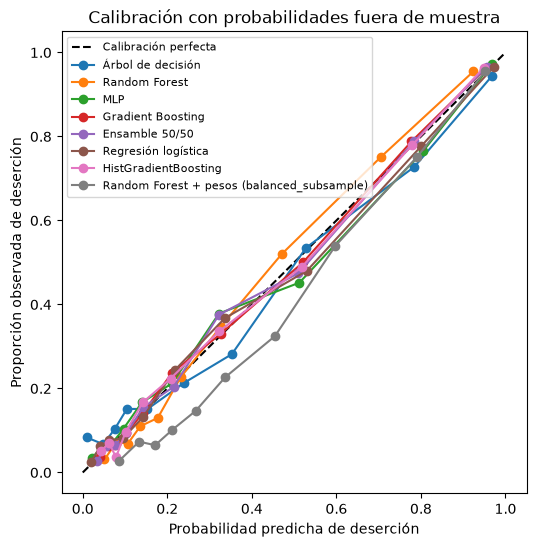

In [31]:
# Brier de cada modelo (menor es mejor), con las probabilidades fuera de muestra de cada pliegue.
display(resumen_operativo[["brier"]].sort_values("brier").round(4))
display(Markdown(f"""
Un Brier sin información, que predice siempre {tasa_desercion:.3f}, es **{tasa_desercion * (1 - tasa_desercion):.3f}**.
"""))

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", label="Calibración perfecta")

for nombre, (_, probabilidades) in evaluaciones.items():
    frecuencia_real, probabilidad_media = calibration_curve(
        y_entrenamiento, probabilidades, n_bins=10, strategy="quantile"
    )
    ax.plot(probabilidad_media, frecuencia_real, marker="o", label=nombre)

ax.set_xlabel("Probabilidad predicha de deserción")
ax.set_ylabel("Proporción observada de deserción")
ax.set_title("Calibración con probabilidades fuera de muestra")
ax.legend(fontsize=8)
plt.show()

In [32]:
display(Markdown("""
### 12.4 Registro en MLFlow

Una corrida por modelo con las medias y desviaciones de los indicadores (precisión y recall entre los primeros K, Brier) y su curva de calibración como imagen. Si la corrida ya existe en el servidor, no se vuelve a crear.
"""))

existentes = corridas_registradas(tipo_registro="metricas_operativas")
creadas = 0

for nombre, (tabla, probabilidades) in evaluaciones.items():
    nombre_run = f"operativas-{nombre}"
    if nombre_run in existentes:
        print(f"Ya registrada: {nombre_run} -> {link_corrida(existentes[nombre_run].info.run_id)}")
        continue

    with mlflow.start_run(run_name=nombre_run):
        mlflow.set_tags({
            "autor": AUTOR,
            "tipo_registro": "metricas_operativas",
            "modelo": nombre,
            "grupo_registro": grupo_felipe,
        })
        mlflow.log_params({
            "fracciones_top_k": str(FRACCIONES),
            "n_pliegues": pliegues.get_n_splits(),
            "n_entrenamiento": len(y_entrenamiento),
            "n_prueba_reservados": len(y_prueba),
        })

        for columna in tabla.columns:
            mlflow.log_metrics({
                f"op_{columna}_mean": float(tabla[columna].mean()),
                f"op_{columna}_std": float(tabla[columna].std(ddof=0)),
            })

        frecuencia_real, probabilidad_media = calibration_curve(
            y_entrenamiento, probabilidades, n_bins=10, strategy="quantile"
        )
        figura, eje = plt.subplots(figsize=(4.5, 4.5))
        eje.plot([0, 1], [0, 1], "k--")
        eje.plot(probabilidad_media, frecuencia_real, marker="o")
        eje.set(
            title=f"Calibración: {nombre}",
            xlabel="Probabilidad predicha",
            ylabel="Proporción observada",
        )
        mlflow.log_figure(figura, "calibracion.png")
        plt.close(figura)
    creadas += 1

print(f"Corridas nuevas: {creadas} de {len(evaluaciones)} modelos.")


### 12.4 Registro en MLFlow

Una corrida por modelo con las medias y desviaciones de los indicadores (precisión y recall entre los primeros K, Brier) y su curva de calibración como imagen. Si la corrida ya existe en el servidor, no se vuelve a crear.


Ya registrada: operativas-Árbol de decisión -> http://54.227.177.156:8050/#/experiments/4/runs/9038c4752fd54ec29bc246bc29e88e5a
Ya registrada: operativas-Random Forest -> http://54.227.177.156:8050/#/experiments/4/runs/925ece6ba3534bfe8daa58dbeae4e2b7
Ya registrada: operativas-MLP -> http://54.227.177.156:8050/#/experiments/4/runs/8d030c71afa3425ebf323ce571586294
Ya registrada: operativas-Gradient Boosting -> http://54.227.177.156:8050/#/experiments/4/runs/607c329b32ca4c54bcb2de9a53b0af0c
Ya registrada: operativas-Ensamble 50/50 -> http://54.227.177.156:8050/#/experiments/4/runs/2d4761c8df964eea8be9c76aab9849a9
Ya registrada: operativas-Regresión logística -> http://54.227.177.156:8050/#/experiments/4/runs/0127824588704b508dd031d5ef2fb448
Ya registrada: operativas-HistGradientBoosting -> http://54.227.177.156:8050/#/experiments/4/runs/7d02872dbf4145e4a2746371cd488d53
Ya registrada: operativas-Random Forest + pesos (balanced_subsample) -> http://54.227.177.156:8050/#/experiments/4/runs/

### 12.5 Modelo final: AP de prueba y registro en MLFlow

La sección 11 calculó la AP en prueba del ensamble 50/50, pero no la guardó en MLFlow. Aquí abrimos de nuevo la corrida original del ensamble, que se busca por su nombre, y le agregamos las métricas de prueba y el modelo entrenado, para poder empaquetarlo en la siguiente entrega.

Es el único modelo que se evalúa en prueba. El modelo se registra para que, al servirlo, devuelva las probabilidades de ambas clases (la columna 1 es la probabilidad de deserción), que es lo que necesita el tablero. Si la corrida ya tiene las métricas y el modelo, la celda no los registra otra vez.

In [33]:
# Corrida original del ensamble (sección 5.5.1): la más antigua con ese nombre. Se busca por nombre
# para no depender de la variable `run_id_ensamble`, que cambia si se vuelve a registrar el ensamble.
corridas_ensamble = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id],
    filter_string="tags.mlflow.runName = 'ensamble-boosting-mlp-50-50'",
    order_by=["attributes.start_time ASC"],
    max_results=1,
    output_format="list",
)
run_id_ensamble_original = corridas_ensamble[0].info.run_id
nombre_modelo_registrado = "desercion-ensamble-boosting-mlp"

metricas_prueba = {
    "test_ap": ap_prueba,
    "test_roc_auc": roc_auc_score(y_prueba, probabilidades_prueba),
    "test_brier": brier_score_loss(y_prueba, probabilidades_prueba),
    **{f"test_{nombre}": valor for nombre, valor in metricas_top_k(y_prueba, probabilidades_prueba).items()},
}
display(pd.Series(metricas_prueba, name="prueba").round(4).to_frame())

# Si la corrida ya tiene las métricas o el modelo, solo se agrega lo que falte.
tiene_metricas = "test_ap" in cliente_mlflow.get_run(run_id_ensamble_original).data.metrics
tiene_modelo = len(cliente_mlflow.search_model_versions(f"name='{nombre_modelo_registrado}'")) > 0

if tiene_metricas and tiene_modelo:
    print("La corrida del ensamble ya tiene las métricas de prueba y el modelo registrado.")
else:
    with mlflow.start_run(run_id=run_id_ensamble_original):
        if not tiene_metricas:
            mlflow.set_tag("evaluacion_prueba_por", AUTOR)
            mlflow.log_metrics({nombre: float(valor) for nombre, valor in metricas_prueba.items()})

        if not tiene_modelo:
            # pyfunc_predict_fn="predict_proba" hace que el modelo servido devuelva probabilidades
            # (columna 0: no deserta, columna 1: deserta) y no la clase 0/1.
            # El nombre del artefacto va como argumento posicional: funciona en MLFlow 2 y 3.
            mlflow.sklearn.log_model(
                modelo_final,
                "modelo",
                signature=infer_signature(X_prueba, modelo_final.predict_proba(X_prueba)),
                input_example=X_prueba.head(3),
                pyfunc_predict_fn="predict_proba",
                registered_model_name=nombre_modelo_registrado,
            )

print(f"Corrida del ensamble: {link_corrida(run_id_ensamble_original)}")
print(f"Modelo registrado: {mlflow.get_tracking_uri()}/#/models/{nombre_modelo_registrado}")

,prueba
test_ap,0.8519
test_roc_auc,0.9000
test_brier,0.1106
test_precision_top_10,0.9886
test_recall_top_10,0.3063
test_precision_top_20,0.8983
test_recall_top_20,0.5599
test_precision_top_30,0.7669
test_recall_top_30,0.7183


La corrida del ensamble ya tiene las métricas de prueba y el modelo registrado.
Corrida del ensamble: http://54.227.177.156:8050/#/experiments/4/runs/aab37a376d1648d69da5da4ce64e8b5d
Modelo registrado: http://54.227.177.156:8050/#/models/desercion-ensamble-boosting-mlp
